In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error

In [24]:
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
stores = pd.read_csv("/content/stores.csv")
features = pd.read_csv("/content/features.csv")

for data in [train, test, features]:
    data['Date'] = pd.to_datetime(data['Date'])

In [25]:
train = train.merge(stores, on='Store', how='left')
test = test.merge(stores, on='Store', how='left')

train = train.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')
test = test.merge(features, on=['Store', 'Date', 'IsHoliday'], how='left')

In [26]:
for data in [train, test]:
    data['Year'] = data['Date'].dt.year
    data['Month'] = data['Date'].dt.month
    data['Week'] = data['Date'].dt.isocalendar().week.astype(int)
    data['Day'] = data['Date'].dt.day

markdowns = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
for col in markdowns:
    if col in train.columns:
        train[col].fillna(0, inplace=True)
        test[col].fillna(0, inplace=True)

for col in ['CPI', 'Unemployment']:
    train[col].fillna(method='ffill', inplace=True)
    test[col].fillna(method='ffill', inplace=True)

train = pd.get_dummies(train, columns=['Type'], drop_first=True)
test = pd.get_dummies(test, columns=['Type'], drop_first=True)

/tmp/ipython-input-26-4062271066.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train[col].fillna(0, inplace=True)
/tmp/ipython-input-26-4062271066.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'd

In [28]:
features = [
    'Store', 'Dept', 'Size', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment',
    'IsHoliday', 'Year', 'Month', 'Week', 'Day',
    'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5',
    'Type_B', 'Type_C'
]

X_train = train[features]
y_train = train['Weekly_Sales']

X_test = test[features]

In [34]:
model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
model.fit(X_train, y_train)

train_preds = model.predict(X_train)
rmse = mean_squared_error(y_train, train_preds)
print("Train RMSE:", rmse)

Train RMSE: 46537083.577078864


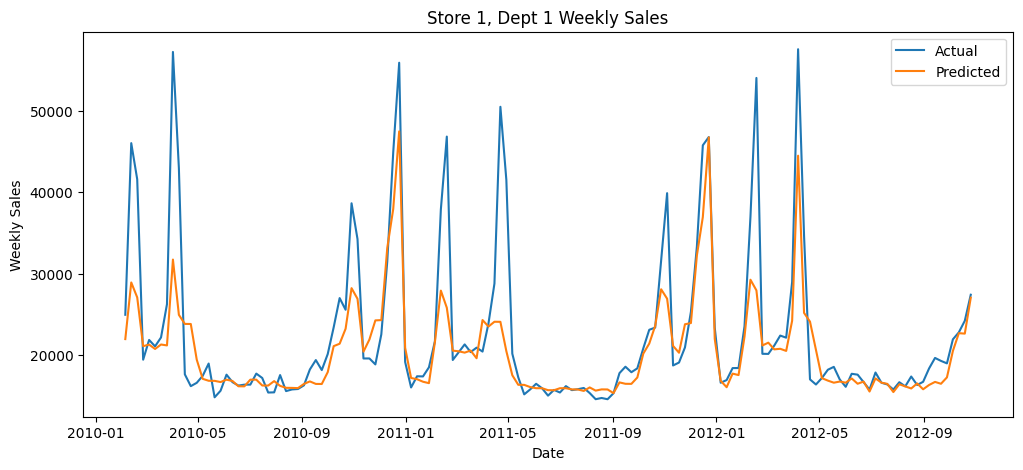

In [35]:
sample = train[(train['Store'] == 1) & (train['Dept'] == 1)].copy()
sample = sample.sort_values('Date')
sample['Pred'] = model.predict(sample[features])

plt.figure(figsize=(12, 5))
plt.plot(sample['Date'], sample['Weekly_Sales'], label='Actual')
plt.plot(sample['Date'], sample['Pred'], label='Predicted')
plt.title('Store 1, Dept 1 Weekly Sales')
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()

In [43]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import lightgbm as lgb

train = train.sort_values(['Store', 'Dept', 'Date'])
train['Sales_Mean_3'] = train.groupby(['Store', 'Dept'])['Weekly_Sales']\
    .transform(lambda x: x.shift(1).rolling(3).mean())
train['Sales_Mean_5'] = train.groupby(['Store', 'Dept'])['Weekly_Sales']\
    .transform(lambda x: x.shift(1).rolling(5).mean())
train[['Sales_Mean_3', 'Sales_Mean_5']] = train[['Sales_Mean_3', 'Sales_Mean_5']].fillna(0)


features += ['Sales_Mean_3', 'Sales_Mean_5']
features = list(dict.fromkeys(features))

X = train[features]
y = train['Weekly_Sales']

tscv = TimeSeriesSplit(n_splits=3)
rmse_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = lgb.LGBMRegressor(n_estimators=100, learning_rate=0.1)
    model.fit(X_tr, y_tr)

    preds = model.predict(X_val)
    rmse = mean_squared_error(y_val, preds)
    rmse_scores.append(rmse)
    print(f"Fold {fold+1} RMSE: {rmse:.2f}")

print(f"\nAverage Cross-Validation RMSE: {np.mean(rmse_scores):.2f}")


Fold 1 RMSE: 38108031.49
Fold 2 RMSE: 20445837.04
Fold 3 RMSE: 14429467.73

Average Cross-Validation RMSE: 24327778.75
